# Mandatory assignment 3

**GitHub repository:** *https://github.com/lirikardsen-jpg/TECH2-H26-assingment3.git*

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

# Step 1

In [151]:
#starting by importign numpy matplotlib and pandas
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt


#loading in the file

file = "SCF_10pct.csv"
df = pd.read_csv(file)


#firstly printing the data set, then finding the number of non-missing values
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB


In [152]:
type(df)

pandas.DataFrame

# Step 2

In [153]:
#starts by defining the variables
variabels = ['id', 'year','age','educ','stocks','equity']

count_before = len(df)
#made a loop to count number of observations that are dropped per variable, found the assingment unclear here 
# and did not know if i needed to add for each separate variable 
for variable in variabels:
    missing = df[variable].isna().sum()
    print (f' dropped {missing} observations from {variable}, there are {len(df)-missing} left before making a new data set')

    
#make a new data set without the observations with missing information, and count these
for variable in variabels:
    df = df.dropna()

count_after = len(df)

print (f'from the original {count_before} observations {count_after} remain, and {count_before - count_after} got dropped ')


 dropped 0 observations from id, there are 5808 left before making a new data set
 dropped 0 observations from year, there are 5808 left before making a new data set
 dropped 0 observations from age, there are 5808 left before making a new data set
 dropped 16 observations from educ, there are 5792 left before making a new data set
 dropped 18 observations from stocks, there are 5790 left before making a new data set
 dropped 16 observations from equity, there are 5792 left before making a new data set
from the original 5808 observations 5758 remain, and 50 got dropped 


# Step 3

In [154]:
obs_before = len(df["age"])

#find the right age and add it to df
right_age = (df["age"]>= 25) & (df["age"]<=89)

df = df[right_age]
obs_after = len(df["age"])

print (f'{obs_before-obs_after} observations were dropped, {obs_after} were kept')



326 observations were dropped, 5432 were kept


# Step 4

In [155]:
#added two new columns to categorise households into direct and overrall 
df["direct"] = (df["stocks"]>0).astype(int)

df["overall"] = (df["equity"]>0).astype(int)

df

,id,year,age,educ,stocks,equity,direct,overall
0,0,1989,35,2.0,0.0,0.0,0,0
1,1,1989,33,2.0,0.0,0.0,0,0
2,2,1989,62,1.0,0.0,0.0,0,0
4,4,1989,70,1.0,0.0,0.0,0,0
5,5,1989,50,1.0,0.0,0.0,0,0
...,...,...,...,...,...,...,...,...
5802,5802,2022,77,3.0,0.0,0.0,0,0
5804,5804,2022,33,3.0,0.0,0.0,0,0
5805,5805,2022,81,2.0,100000.0,100000.0,1,1
5806,5806,2022,58,3.0,40000.0,1212000.0,1,1


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

# Step 1

In [156]:


def participation_rate(indicator):
    participants = 0
    for value in indicator:
        if value == 1:
                
            participants += 1

    percentage = (participants/len(indicator))*100

    return (round(percentage,1))



# Step 2

In [157]:

print (f' the direct participaiton rate is {participation_rate(df['direct'])}%')

print (f' the overall participation rate is {participation_rate(df['overall'])}%')

 the direct participaiton rate is 17.0%
 the overall participation rate is 49.4%


# Step 3

In [158]:
direct_part = df["direct"].mean()*100

overall_part = df["overall"].mean()*100

print (f' the direct participaiton rate is {direct_part}')
print (f' the overall participaiton rate is {overall_part}')

 the direct participaiton rate is 16.955081001472756
 the overall participaiton rate is 49.41089837997055


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

# Step 1

In [159]:
direct_rates = []
overall_rates = []

for educ_level in [1,2,3,4]:
    category_e = df[df["educ"] == educ_level]
    direct_rate = participation_rate(category_e['direct'])
    overall_rate = participation_rate(category_e['overall'])
    direct_rates.append(direct_rate)
    overall_rates.append(overall_rate)

                    
            

# Step 2

In [160]:


for educ_level in [1,2,3,4]:
  
    print (f' the direct participaiton rate in education level {educ_level}  is {direct_rates[educ_level-1]}%')
    print (f' the overall participaiton rate in education level {educ_level} is {overall_rates[educ_level-1]}%')










                    

 the direct participaiton rate in education level 1  is 4.4%
 the overall participaiton rate in education level 1 is 17.3%
 the direct participaiton rate in education level 2  is 11.4%
 the overall participaiton rate in education level 2 is 39.9%
 the direct participaiton rate in education level 3  is 13.5%
 the overall participaiton rate in education level 3 is 48.3%
 the direct participaiton rate in education level 4  is 30.5%
 the overall participaiton rate in education level 4 is 73.5%


# Step 3

C:\Users\lirik\AppData\Local\Temp\ipykernel_5392\2898123413.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(labels, rotation=45, ha = 'right')
C:\Users\lirik\AppData\Local\Temp\ipykernel_5392\2898123413.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(labels, rotation=45, ha = 'right')


Text(0.5, 1.0, 'overal participation')

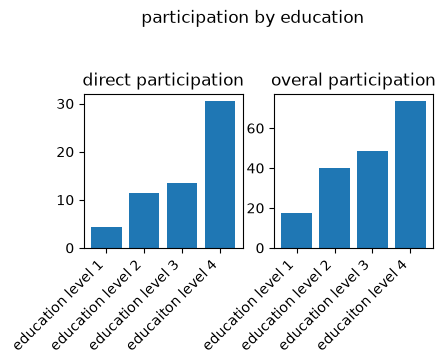

In [161]:
# creating the figure
fig, axes = plt.subplots(1,2,figsize=(4.5,2))

labels = ['education level 1', 'education level 2', 'education level 3','educaiton level 4']

#give my values to a variable i can use when plotting my bar chart
values1 = direct_rates
values2 = overall_rates

#plots the bar chart
axes[0].bar(labels,values1, label = 'participation rate')
axes[1].bar(labels,values2, label = 'participation rate')

axes[0].set_xticklabels(labels, rotation=45, ha = 'right')
axes[1].set_xticklabels(labels, rotation=45, ha = 'right')

#put on title, and move the suptitle higher up
fig.suptitle("participation by education", y =1.3)
axes[0].set_title("direct participation")
axes[1].set_title("overal participation")



# Step 4

the participation rates, both direct and overall, follow a clear pattern when it comes to education level. the higher education level you have, the more active you are. 

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

# Step 1

In [188]:
# make epmty lists to fill
direct_rates_y = []
overall_rates_y = []


#the survey is done my many households, this gathers them into each year
years = sorted(df['year'].unique())

for year in years:
    rate_per_year = df[df['year'] == year]
    direct_rate = participation_rate(rate_per_year['direct'])
    overall_rate = participation_rate(rate_per_year['overall'])
    direct_rates_y.append(direct_rate)
    overall_rates_y.append(overall_rate)

print (direct_rates_y)

[15.6, 18.3, 15.7, 19.9, 21.8, 18.9, 17.3, 17.4, 14.8, 12.3, 12.4, 19.2]


# Step 2

Text(0.5, 1.0, 'overal participation')

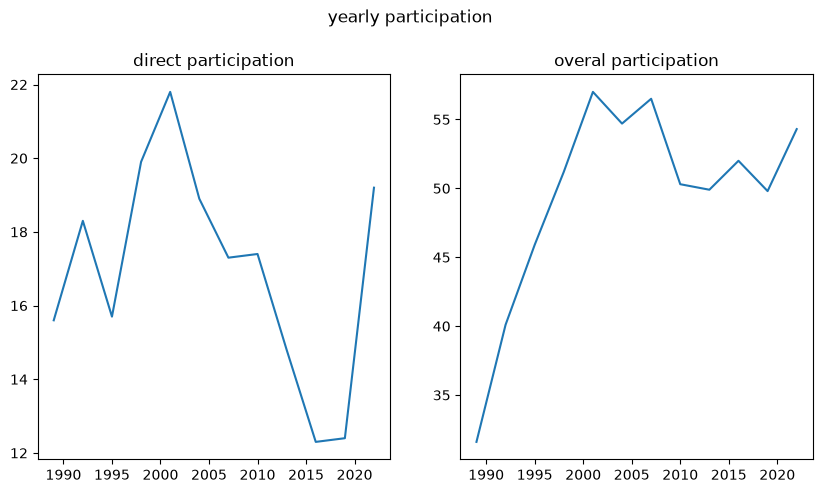

In [184]:
# creating the figure
fig, axes = plt.subplots(1,2,figsize=(10,5))

#assign the values
x_value = years
y_values1 = direct_rates_y
y_values2 = overall_rates_y

#plots the graphs in
axes[0].plot(x_value,y_values1)
axes[1].plot(x_value,y_values2)

#put on title, and move the suptitle higher up
fig.suptitle("yearly participation ", y =1.01)
axes[0].set_title("direct participation")
axes[1].set_title("overal participation")



# Step 3

In [195]:
# i set a count to find the values in the list
i = 0
for years in range(1989,2023,3):
     print (f' in {years} the direct participation rate was {direct_rates_y[i]} % while the overall participation rate was {overall_rates_y[i]} %')
     i += 1

 in 1989 the direct participation rate was 15.6 % while the overall participation rate was 31.6 %
 in 1992 the direct participation rate was 18.3 % while the overall participation rate was 40.1 %
 in 1995 the direct participation rate was 15.7 % while the overall participation rate was 45.9 %
 in 1998 the direct participation rate was 19.9 % while the overall participation rate was 51.2 %
 in 2001 the direct participation rate was 21.8 % while the overall participation rate was 57.0 %
 in 2004 the direct participation rate was 18.9 % while the overall participation rate was 54.7 %
 in 2007 the direct participation rate was 17.3 % while the overall participation rate was 56.5 %
 in 2010 the direct participation rate was 17.4 % while the overall participation rate was 50.3 %
 in 2013 the direct participation rate was 14.8 % while the overall participation rate was 49.9 %
 in 2016 the direct participation rate was 12.3 % while the overall participation rate was 52.0 %
 in 2019 the direct 

# Step 4

we can see that both participation rates rise around the year 2000, but fall substantially after 2005. they also move up again around 2022, the last year the survey was taken.

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

# Statement

used AI to explain the task when i didnt understand it, and to help me find different types of commands like .dropna(). also used it to help me explain mistakes, and in some cases to give hint about how i should perceed when i got stuck.